# Lab 1: Meta regression

## Questions
- Did Facebook users grow in a straight line, or does a quadratic trend fit better?
- Is employee count related to revenue or profit?

## Plan
- Fit initial models using the assignment data through 2017.
- Compare their forecasts with actuals for 2018–2020, 2021–2023, and 2024–2025.

## Check
- Note missing quarters and whether later user counts use the same definition.

In [3]:
from pathlib import Path
import pandas as pd
workbook = Path("../data/raw/MED-Lab-1-Zadanie-1-Dane.xlsx")

users = pd.read_excel(workbook, sheet_name=3, header=1)

users = users.dropna(subset=["Users"])[["QY", "Users"]].copy()
users.columns = ["quarter", "users_millions"]

# Extract quarter and two-digit year from labels such as Q3 '08.
parts = users["quarter"].str.extract(r"Q([1-4])\s*'(\d{2})")
users["quarter_num"] = parts[0].astype(int)
users["year"] = 2000 + parts[1].astype(int)

# Give each calendar quarter a number; Q3 2008 is time 0.
users["time"] = (users["year"] - 2008) * 4 + users["quarter_num"] - 3

# The assignment tables go through 2017.
initial_users = users[users["year"] <= 2017].copy()
later_users = users[users["year"] >= 2018].copy()

print("Initial data:", initial_users.shape)
display(initial_users.head())
display(initial_users.tail())

print("Later data for forecast checks:", later_users.shape)
display(later_users.head())

Initial data: (37, 5)


,quarter,users_millions,quarter_num,year,time
0,Q3 '08,100.0,3,2008,0
1,Q1 '09,197.0,1,2009,2
2,Q2 '09,242.0,2,2009,3
3,Q3 '09,305.0,3,2009,4
4,Q4 '09,360.0,4,2009,5


,quarter,users_millions,quarter_num,year,time
32,Q4 '16,1860.0,4,2016,33
33,Q1 '17,1936.0,1,2017,34
34,Q2 '17,2006.0,2,2017,35
35,Q3 '17,2072.0,3,2017,36
36,Q4 '17,2129.0,4,2017,37


Later data for forecast checks: (24, 5)


,quarter,users_millions,quarter_num,year,time
37,Q1 '18,2196.0,1,2018,38
38,Q2 '18,2234.0,2,2018,39
39,Q3 '18,2271.0,3,2018,40
40,Q4 '18,2320.0,4,2018,41
41,Q1 '19,2375.0,1,2019,42


In [14]:
annual = pd.read_excel(workbook,sheet_name=1, header=1)
annual.columns = ["year", "revenue", "profit", "employees"]
#annual = annual.apply(pd.to_numeric, errors="coerce").dropna()
annual.isna().sum()
print(annual.columns)
display(annual)


Index(['year', 'revenue', 'profit', 'employees'], dtype='str')


,year,revenue,profit,employees
0,2007,153,-138,450
1,2008,272,-56,850
2,2009,777,229,1218
3,2010,1974,606,2127
4,2011,3711,1000,3200
5,2012,5089,53,4619
6,2013,7872,1500,6337
7,2014,12466,2940,9199
8,2015,17928,3688,12691
9,2016,27638,10217,17048


In [10]:
correlations = annual.corr()
display(correlations.round(2))

,year,revenue,profit,employees
year,1.00,0.89,0.80,0.92
revenue,0.89,1.00,0.98,1.00
profit,0.80,0.98,1.00,0.96
employees,0.92,1.00,0.96,1.00


# Wnioski

### We see strong corellations, year with profit (.92), revenue with profit (.98) and revenue with employment(1.00). Last value may actually be very close to e.

That shows us that the values moved together over the 11 years, not necessarily causation, Revenue and employment may both rise with time, whilst also pointing out that profit had sharp dip in 2012.

We will do scatter plat to see relationship over time


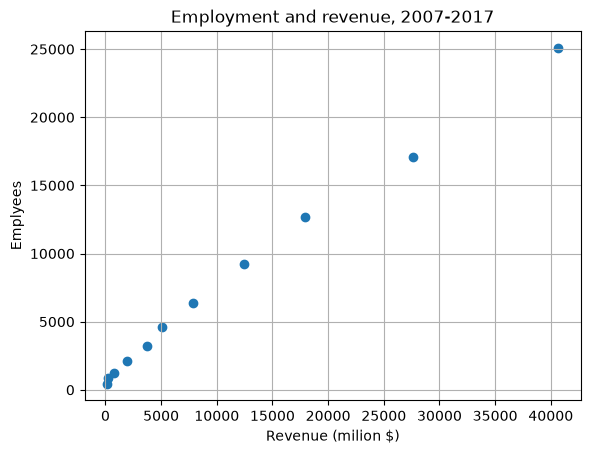

In [19]:
import matplotlib.pyplot as plt

plt.scatter(annual["revenue"], annual["employees"])

plt.xlabel("Revenue (milion $)")
plt.ylabel("Emplyees")
plt.title("Employment and revenue, 2007-2017")
plt.grid(True)
plt.show()

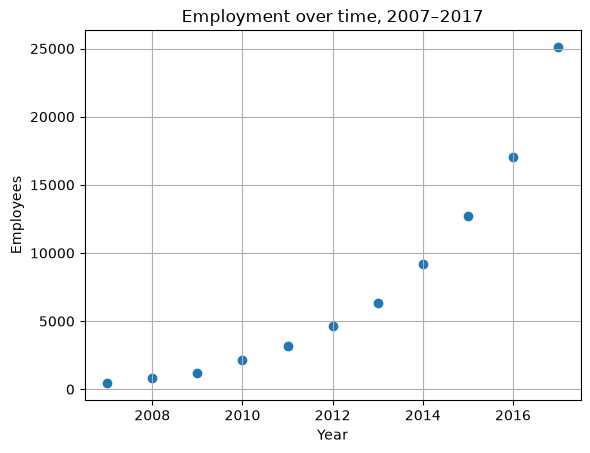

In [18]:
plt.scatter(annual["year"], annual["employees"])
plt.xlabel("Year")
plt.ylabel("Employees")
plt.title("Employment over time, 2007–2017")
plt.grid(True)
plt.show()

In [20]:
changes = pd.DataFrame({
    "year": annual["year"],
    "employees": annual["employees"],
    "change_from_previous_year": annual["employees"].diff(),
    "change_in_annual_change": annual["employees"].diff().diff(),
})

display(changes)

,year,employees,change_from_previous_year,change_in_annual_change
0,2007,450,NaN,NaN
1,2008,850,400.0,NaN
2,2009,1218,368.0,-32.0
3,2010,2127,909.0,541.0
4,2011,3200,1073.0,164.0
5,2012,4619,1419.0,346.0
6,2013,6337,1718.0,299.0
7,2014,9199,2862.0,1144.0
8,2015,12691,3492.0,630.0
9,2016,17048,4357.0,865.0


## Initial observations and candidate models

- Annual revenue, profit, and employment generally rise over 2007–2017. Their correlations are strong, but all three may also be related to time. Correlation alone does not show causation.
- Employment versus revenue looks roughly linear, albeit it might have a slight downard trend. I’ll use a linear model as the baseline and test a quadratic only as a comparison.
- Employment versus year looks more curved. A quadratic trend may be useful to test, but the large 2017 increase could influence the result, will need further testing.
- Profit has a noticeable dip in 2012, so I’ll check how that observation affects any model involving profit.
- For quarterly Facebook users, I’ll compare linear and quadratic trends using the assignment data through 2017.

These are initial observations, not conclusions. I’ll choose models after checking the fit and residuals.

In [24]:
#Initial linear baseline for annual employment vesrur revenue


import statsmodels.formula.api as smf

annual["revenue_billions"] = annual["revenue"] / 1000

linear_emp_revenue = smf.ols(
    "employees ~ revenue_billions",
    data=annual,
).fit()

print(linear_emp_revenue.summary())

                            OLS Regression Results                            
Dep. Variable:              employees   R-squared:                       0.995
Model:                            OLS   Adj. R-squared:                  0.995
Method:                 Least Squares   F-statistic:                     1866.
Date:                Sat, 07 Nov 2026   Prob (F-statistic):           9.53e-12
Time:                        23:14:22   Log-Likelihood:                -84.414
No. Observations:                  11   AIC:                             172.8
Df Residuals:                       9   BIC:                             173.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept         1074.6305    229.039  

In [25]:
annual["revenue_centered"] = (
    annual["revenue_billions"] - annual["revenue_billions"].mean()
)

quadratic_emp_revenue = smf.ols(
    "employees ~ revenue_centered + I(revenue_centered ** 2)",
    data=annual,
).fit()

print(quadratic_emp_revenue.summary())

                            OLS Regression Results                            
Dep. Variable:              employees   R-squared:                       0.997
Model:                            OLS   Adj. R-squared:                  0.997
Method:                 Least Squares   F-statistic:                     1582.
Date:                Sat, 07 Nov 2026   Prob (F-statistic):           4.05e-11
Time:                        23:15:23   Log-Likelihood:                -80.877
No. Observations:                  11   AIC:                             167.8
Df Residuals:                       8   BIC:                             168.9
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

### Observations
 The squared term is negative which support the thought that employment versur revenue bends slighty downowards. (wklęsła).
#The squared term p value is 0.028 , under normal 5% level we reject H0. 
R^2 rises from 0.995 to 0.997, a small incrasese, with 11 obsercations it is evidance of curvature in the sample, we cannot judge as a reliable model.